# SaaS Subscription Churn Analysis

- Calculate churn rate by plan, billing cycle, acquisition channel, and company size.
- Identify the highest-risk segments.

In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import seaborn as sns

In [3]:
%load_ext sql
%config SqlMagic.autopandas = True
%sql duckdb://

Connecting to 'duckdb://'

In [4]:
%%sql
CREATE OR REPLACE TABLE subscriptions AS SELECT * FROM read_csv_auto('data/subscriptions.csv');

Running query in 'duckdb://'

,Success


In [5]:
%%sql
CREATE OR REPLACE TABLE monthly_revenue AS SELECT * FROM read_csv_auto('data/monthly_revenue.csv');

Running query in 'duckdb://'

,Success


In [6]:
%%sql

SELECT ROUND(SUM(churned_customers) / SUM(total_active_customers), 2) AS churn_rate
FROM monthly_revenue;


Running query in 'duckdb://'

,churn_rate
0,0.04


In [7]:
%%sql result_1 <<
SELECT month, churned_customers, total_active_customers, ROUND(churned_customers / total_active_customers, 2) AS churn_rate
FROM monthly_revenue
ORDER BY month DESC;

Running query in 'duckdb://'

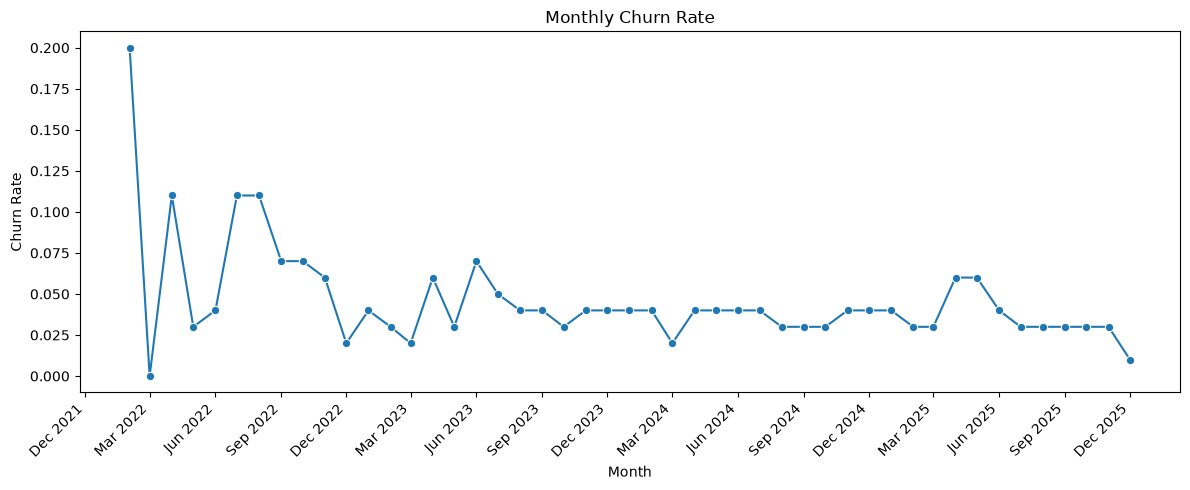

In [8]:
result_1["month"] = pd.to_datetime(result_1["month"])
result_1 = result_1.sort_values("month")

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=result_1, x="month", y="churn_rate", marker="o", ax=ax)

ax.set_title("Monthly Churn Rate")
ax.set_xlabel("Month")
ax.set_ylabel("Churn Rate")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Over the last four years the churn rate decreased steadily only spiked to 7.5% around May and June 2025. 

In [9]:
%%sql result_2 <<

SELECT billing_cycle,
       plan, 
       SUM(CASE WHEN churned = true THEN 1 ELSE 0 END) AS num_churned_clients,
       ROUND(SUM(CASE WHEN churned = true THEN 1 ELSE 0 END)*1.0 / COUNT(*),2) AS plan_churned_rate,
       
FROM subscriptions
GROUP BY plan, billing_cycle
ORDER BY CASE plan
          WHEN 'Starter' THEN 1
          WHEN 'Professional' THEN 2
          WHEN 'Business' THEN 3
          WHEN 'Enterprise' THEN 4
         END;


Running query in 'duckdb://'

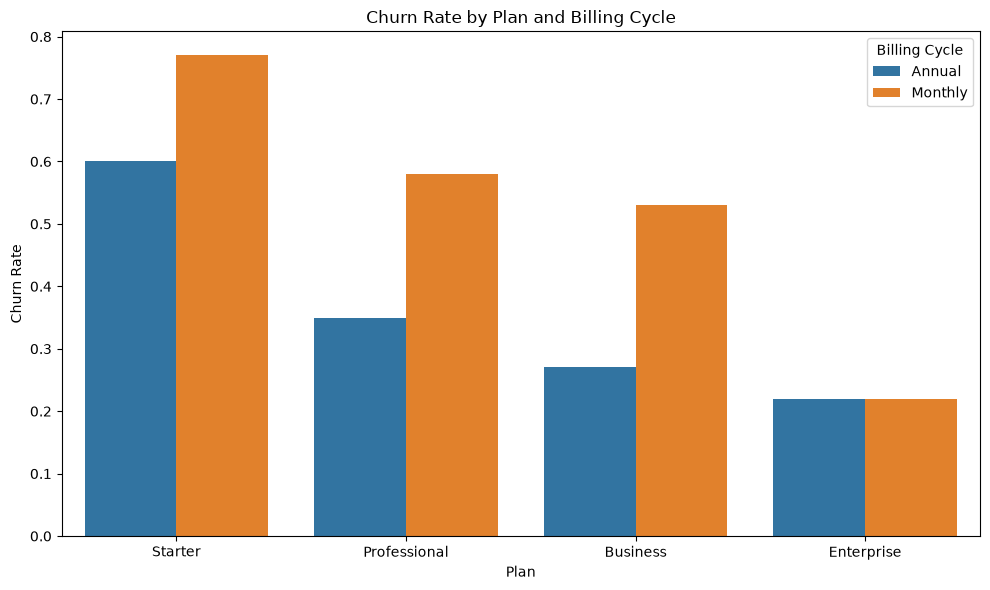

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=result_2, x="plan", y="plan_churned_rate", hue="billing_cycle", ax=ax)

ax.set_title("Churn Rate by Plan and Billing Cycle")
ax.set_xlabel("Plan")
ax.set_ylabel("Churn Rate")
ax.legend(title="Billing Cycle")

plt.tight_layout()
plt.show()


In [11]:
%%sql result_3 <<
SELECT company_size,
       COALESCE(acquisition_channel, 'All Channels') AS acquisition_channel,
       SUM(CASE WHEN churned = true THEN 1 ELSE 0 END) AS num_churned_clients,
       COUNT(*) AS num_clients,
       ROUND(SUM(CASE WHEN churned = true THEN 1 ELSE 0 END) * 1.0 / COUNT(*), 2) AS churn_rate
FROM subscriptions
GROUP BY GROUPING SETS ((company_size, acquisition_channel), (company_size))
ORDER BY CASE company_size
          WHEN '1-10' THEN 1
          WHEN '11-50' THEN 2
          WHEN '51-200' THEN 3
          WHEN '201-500' THEN 4
          WHEN '500+' THEN 5
         END,
         acquisition_channel NULLS LAST;

Running query in 'duckdb://'

In [12]:
%%sql result_6 <<
SELECT acquisition_channel, company_size, churned
FROM subscriptions;

Running query in 'duckdb://'

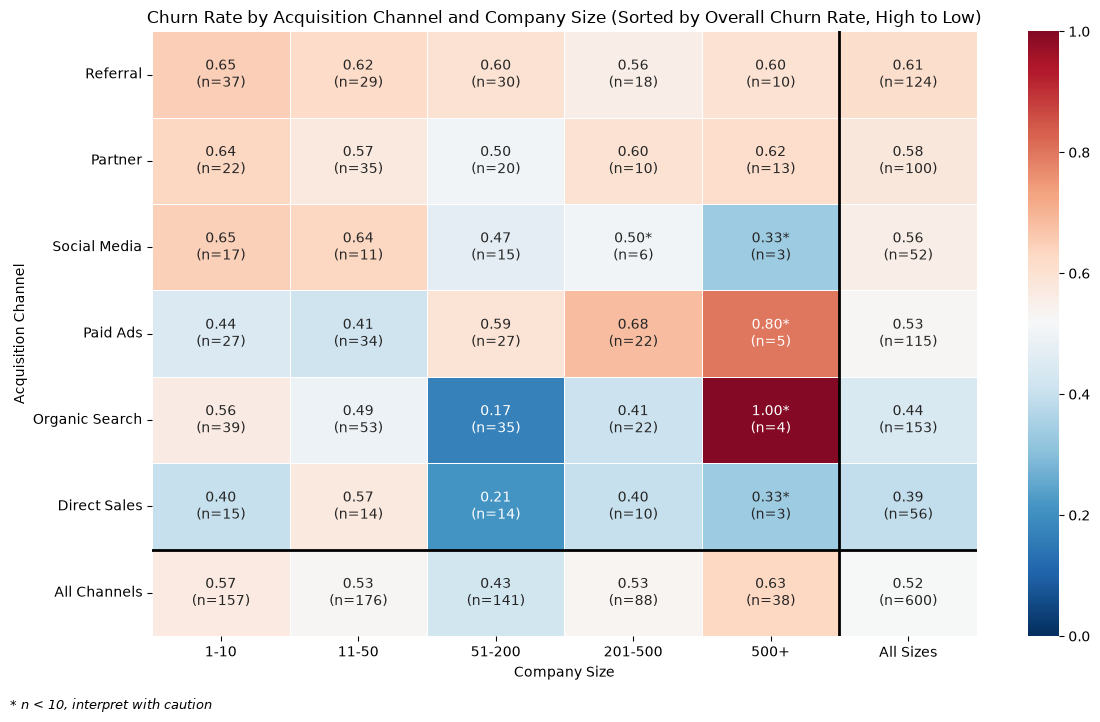

In [13]:
import os

size_order = ["1-10", "11-50", "51-200", "201-500", "500+"]
SMALL_N_THRESHOLD = 10

channel_size_df = result_6.copy()
channel_size_df["churned"] = channel_size_df["churned"].astype(int)

pivot = channel_size_df.pivot_table(
    index="acquisition_channel", columns="company_size", values="churned", aggfunc="mean"
).reindex(columns=size_order)
counts = channel_size_df.pivot_table(
    index="acquisition_channel", columns="company_size", values="churned", aggfunc="count"
).reindex(columns=size_order).astype(int)

channel_totals = channel_size_df.groupby("acquisition_channel")["churned"].agg(["mean", "count"])
pivot["All Sizes"] = channel_totals["mean"]
counts["All Sizes"] = channel_totals["count"].astype(int)

pivot = pivot.sort_values("All Sizes", ascending=False)
counts = counts.loc[pivot.index]

size_totals = channel_size_df.groupby("company_size")["churned"].agg(["mean", "count"]).reindex(size_order)
overall_rate = channel_size_df["churned"].mean()
overall_n = len(channel_size_df)

all_channels_rate = pd.concat([size_totals["mean"], pd.Series({"All Sizes": overall_rate})])
all_channels_n = pd.concat([size_totals["count"], pd.Series({"All Sizes": overall_n})]).astype(int)

pivot.loc["All Channels"] = all_channels_rate
counts.loc["All Channels"] = all_channels_n

def fmt_cell(rate, n):
    flag = "*" if n < SMALL_N_THRESHOLD else ""
    return f"{rate:.2f}{flag}\n(n={n})"

annot = pd.DataFrame(
    [[fmt_cell(pivot.iloc[i, j], counts.iloc[i, j]) for j in range(pivot.shape[1])] for i in range(pivot.shape[0])],
    index=pivot.index,
    columns=pivot.columns,
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    pivot, annot=annot, fmt="", vmin=0, vmax=1, center=overall_rate,
    cmap="RdBu_r", linewidths=0.5, ax=ax,
)
ax.axvline(x=len(size_order), color="black", linewidth=2)
ax.axhline(y=len(pivot) - 1, color="black", linewidth=2)

ax.set_title("Churn Rate by Acquisition Channel and Company Size (Sorted by Overall Churn Rate, High to Low)")
ax.set_xlabel("Company Size")
ax.set_ylabel("Acquisition Channel")

if (counts.to_numpy() < SMALL_N_THRESHOLD).any():
    fig.text(0.01, -0.02, f"* n < {SMALL_N_THRESHOLD}, interpret with caution", fontsize=9, style="italic")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/churn_heatmap_channel_size.png", dpi=200, bbox_inches="tight")

plt.show()

The "All Channels" row shows 51-200 has the lowest churn of any size bucket (0.43, vs. 0.52 overall), and that's driven by Organic Search (0.17) and Direct Sales (0.21) — the two lowest cells in the entire table. Every other channel's 51-200 column sits closer to its own overall rate, so this dip is concentrated in those two channels rather than a general "mid-size companies churn less" effect.

## Does Plan Affect Churn? Testing the Relationship Statistically

The chart above (`result_2`) shows churn rate varies a lot by plan and billing cycle, but it doesn't tell us whether that variation is bigger than we'd expect from chance, or how much of it is really about plan versus billing cycle itself. The next two steps test this directly: first a chi-square test of independence on plan × churn, then a logistic regression that controls for billing cycle.

In [14]:
%%sql result_5 <<
SELECT plan, billing_cycle, churned
FROM subscriptions;

Running query in 'duckdb://'

In [15]:
plan_churn_crosstab = pd.crosstab(result_5["plan"], result_5["churned"])
plan_churn_crosstab = plan_churn_crosstab.rename(columns={False: "retained", True: "churned"})
plan_churn_crosstab

churned,retained,churned
plan,,
Business,94,66
Enterprise,39,11
Professional,90,83
Starter,64,153


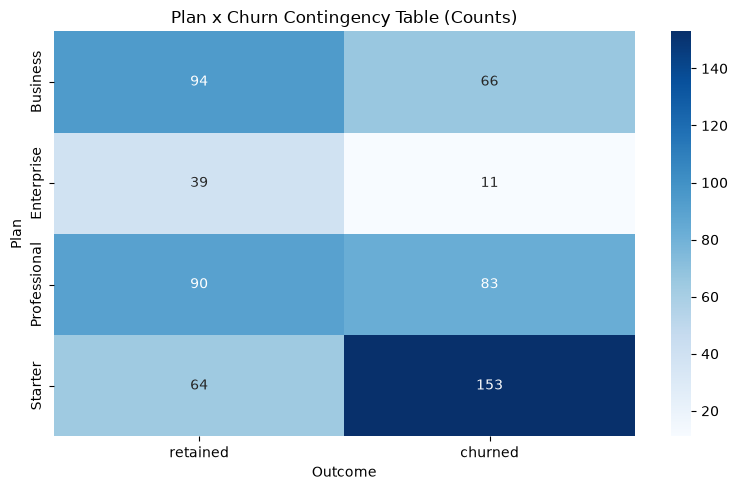

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(plan_churn_crosstab, annot=True, fmt="d", cmap="Blues", ax=ax)

ax.set_title("Plan x Churn Contingency Table (Counts)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Plan")

plt.tight_layout()
plt.show()

In [17]:
from statsmodels.stats.contingency_tables import Table

plan_churn_table = Table(plan_churn_crosstab)
chi2_result = plan_churn_table.test_nominal_association()

print(f"Chi-square statistic: {chi2_result.statistic:.3f}")
print(f"Degrees of freedom:   {chi2_result.df}")
print(f"P-value:              {chi2_result.pvalue:.6g}")

Chi-square statistic: 56.345
Degrees of freedom:   3
P-value:              3.54639e-12


### Chi-Square Test: Plan and Churn Association

The chi-square test of independence on the plan × churn table gives χ² = 56.345, df = 3, p = 3.5e-12. Since p is far below the conventional 0.05 threshold, we reject the null hypothesis that plan and churn are independent — plan is statistically associated with whether a customer churns.

This lines up with `result_2`, where churn rates differ sharply across plan (Starter is churning far more than Enterprise). A chi-square test only tells us *that* an association exists, though — it can't separate plan's own effect from billing cycle, which might be correlated with plan. The logistic regression below addresses that.

In [18]:
import statsmodels.formula.api as smf

logit_df = result_5.copy()
logit_df["churned"] = logit_df["churned"].astype(int)

logit_model = smf.logit(
    "churned ~ C(plan, Treatment(reference='Starter')) * C(billing_cycle)",
    data=logit_df,
).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.621799
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                  600
Model:                          Logit   Df Residuals:                      592
Method:                           MLE   Df Model:                            7
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                  0.1017
Time:                        13:55:10   Log-Likelihood:                -373.08
converged:                       True   LL-Null:                       -415.32
Covariance Type:            nonrobust   LLR p-value:                 1.667e-15
                                                                                          coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------

In [19]:
import math

odds_ratios = pd.DataFrame({
    "coef": logit_model.params,
    "odds_ratio": logit_model.params.apply(math.exp),
    "ci_lower_or": logit_model.conf_int()[0].apply(math.exp),
    "ci_upper_or": logit_model.conf_int()[1].apply(math.exp),
    "p_value": logit_model.pvalues,
})
odds_ratios

,coef,odds_ratio,ci_lower_or,ci_upper_or,p_value
Intercept,0.415515,1.515152,0.976216,2.351616,0.063935
"C(plan, Treatment(reference='Starter'))[T.Business]",-1.390075,0.249057,0.126606,0.489940,0.000057
"C(plan, Treatment(reference='Starter'))[T.Enterprise]",-1.668278,0.188571,0.057082,0.622948,0.006215
"C(plan, Treatment(reference='Starter'))[T.Professional]",-1.028620,0.357500,0.186845,0.684024,0.001889
C(billing_cycle)[T.Monthly],0.785226,2.192903,1.209091,3.977224,0.009737
"C(plan, Treatment(reference='Starter'))[T.Business]:C(billing_cycle)[T.Monthly]",0.304403,1.355815,0.555491,3.309204,0.503734
"C(plan, Treatment(reference='Starter'))[T.Enterprise]:C(billing_cycle)[T.Monthly]",-0.805429,0.446896,0.098348,2.030716,0.297040
"C(plan, Treatment(reference='Starter'))[T.Professional]:C(billing_cycle)[T.Monthly]",0.133260,1.142547,0.483065,2.702356,0.761587


In [20]:
from scipy.stats import chi2

logit_additive_model = smf.logit(
    "churned ~ C(plan, Treatment(reference='Starter')) + C(billing_cycle)",
    data=logit_df,
).fit()

lr_stat_interaction = 2 * (logit_model.llf - logit_additive_model.llf)
lr_df_interaction = logit_model.df_model - logit_additive_model.df_model
lr_pvalue_interaction = chi2.sf(lr_stat_interaction, lr_df_interaction)

print(f"LR statistic: {lr_stat_interaction:.3f}")
print(f"Degrees of freedom: {lr_df_interaction}")
print(f"P-value: {lr_pvalue_interaction:.6g}")
print(f"\nAdditive model (no interaction):    AIC = {logit_additive_model.aic:.1f}, BIC = {logit_additive_model.bic:.1f}")
print(f"Interaction model:                   AIC = {logit_model.aic:.1f}, BIC = {logit_model.bic:.1f}")

Optimization terminated successfully.
         Current function value: 0.623470
         Iterations 5
LR statistic: 2.004
Degrees of freedom: 3.0
P-value: 0.571477

Additive model (no interaction):    AIC = 758.2, BIC = 780.1
Interaction model:                   AIC = 762.2, BIC = 797.3


### Logistic Regression: Plan's Effect on Churn, Controlling for Billing Cycle

The model includes a `plan × billing_cycle` interaction to test whether billing cycle's effect on churn differs by plan. None of the three interaction terms are individually significant (Business×Monthly p = 0.50, Enterprise×Monthly p = 0.30, Professional×Monthly p = 0.76), and a likelihood-ratio test of all three jointly confirms it (LR = 2.004, df = 3, p = 0.57) — there's no evidence that billing cycle matters more or less for any particular plan. The relationship is additive: plan and billing cycle each independently shift churn risk, rather than billing cycle amplifying or dampening a specific plan's risk.

With the interaction included, the main effects (representing each factor's effect within the Annual/Starter baseline) point the same direction as the simpler model: relative to Starter on Annual billing, Business (OR = 0.25, p < 0.001), Professional (OR = 0.36, p = 0.002), and Enterprise (OR = 0.19, p = 0.006) all have significantly lower odds of churn, and Monthly billing raises odds 2.19x over Annual (p = 0.01) at the Starter level.

The interaction model also fits worse once complexity is penalized — AIC 762.2 vs. 758.2, and BIC 797.3 vs. 780.1 for the simpler additive model — so the additive model is both statistically justified and more parsimonious: plan has a steady, graded effect on churn (Starter > Professional > Business > Enterprise), and billing cycle adds an independent risk on top of that regardless of plan. Consistent with `result_2`: Starter + Monthly has the highest churn rate, Enterprise + Annual the lowest, and that gap is explained by plan and billing cycle adding up, not interacting.

## Does Billing Cycle Affect Churn?

`billing_cycle` showed up as a significant covariate inside the plan model above (Monthly OR = 2.18 vs. Annual, p = 0.01), but that only tells us billing cycle matters *given* plan — it doesn't confirm billing cycle and churn are associated on their own. The same chi-square test used for plan answers that directly.

In [21]:
billing_churn_crosstab = pd.crosstab(result_5["billing_cycle"], result_5["churned"])
billing_churn_crosstab = billing_churn_crosstab.rename(columns={False: "retained", True: "churned"})
billing_churn_crosstab

churned,retained,churned
billing_cycle,,
Annual,148,100
Monthly,139,213


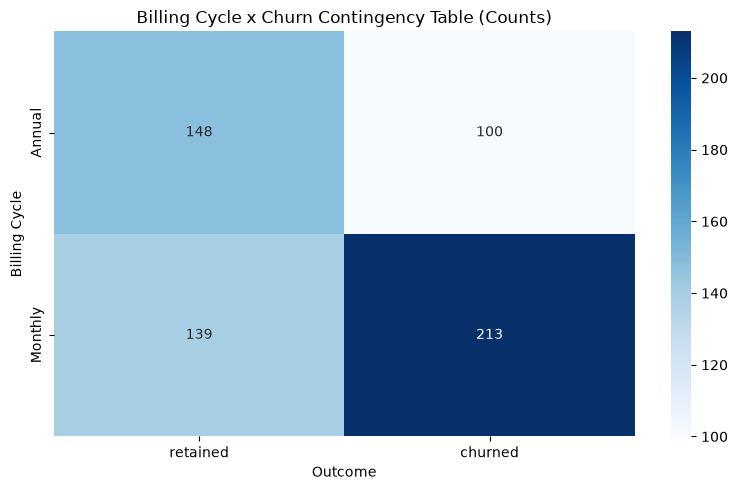

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(billing_churn_crosstab, annot=True, fmt="d", cmap="Blues", ax=ax)

ax.set_title("Billing Cycle x Churn Contingency Table (Counts)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Billing Cycle")

plt.tight_layout()
plt.show()

In [23]:
billing_churn_table = Table(billing_churn_crosstab)
chi2_result_billing = billing_churn_table.test_nominal_association()

print(f"Chi-square statistic: {chi2_result_billing.statistic:.3f}")
print(f"Degrees of freedom:   {chi2_result_billing.df}")
print(f"P-value:              {chi2_result_billing.pvalue:.6g}")

Chi-square statistic: 23.765
Degrees of freedom:   1
P-value:              1.08838e-06


### Chi-Square Test: Billing Cycle and Churn Association

The chi-square test on the billing_cycle × churn table gives χ² = 23.765, df = 1, p = 1.1e-06 — well below 0.05, so billing cycle and churn are not independent. The crosstab shows why: Annual customers churn at 40% (100 of 248), while Monthly customers churn at 61% (213 of 352). This confirms, on its own and without controlling for anything else, that billing cycle is associated with churn — consistent with (and now independently verifying) the OR = 2.18 effect billing cycle showed as a covariate in the plan regression above.

## Does Acquisition Channel Affect Churn?

The channel x company-size heatmap earlier showed channel-level differences — Organic Search and Direct Sales trended lower than the other channels. The chi-square test below checks whether `acquisition_channel` on its own is associated with churn.

In [24]:
channel_churn_crosstab = pd.crosstab(result_6["acquisition_channel"], result_6["churned"])
channel_churn_crosstab = channel_churn_crosstab.rename(columns={False: "retained", True: "churned"})
channel_churn_crosstab

churned,retained,churned
acquisition_channel,,
Direct Sales,34,22
Organic Search,86,67
Paid Ads,54,61
Partner,42,58
Referral,48,76
Social Media,23,29


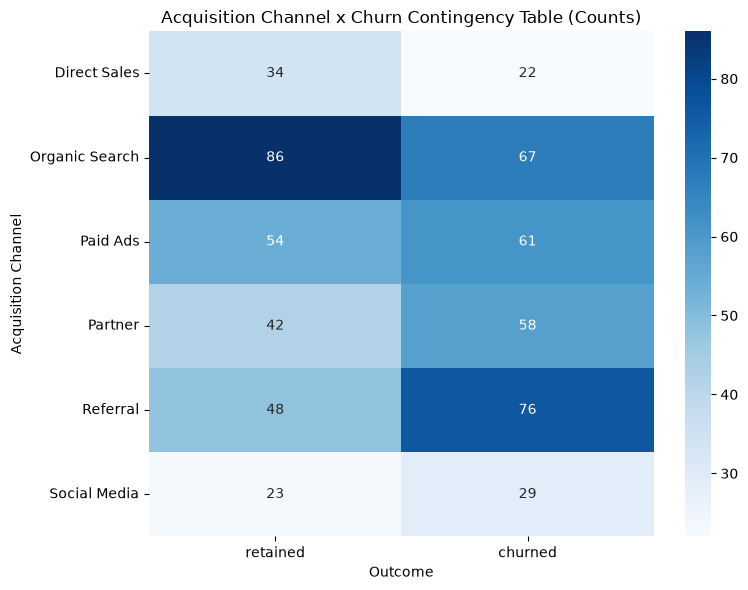

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(channel_churn_crosstab, annot=True, fmt="d", cmap="Blues", ax=ax)

ax.set_title("Acquisition Channel x Churn Contingency Table (Counts)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Acquisition Channel")

plt.tight_layout()
plt.show()

In [26]:
channel_churn_table = Table(channel_churn_crosstab)
chi2_result_channel = channel_churn_table.test_nominal_association()

print(f"Chi-square statistic: {chi2_result_channel.statistic:.3f}")
print(f"Degrees of freedom:   {chi2_result_channel.df}")
print(f"P-value:              {chi2_result_channel.pvalue:.6g}")

Chi-square statistic: 13.831
Degrees of freedom:   5
P-value:              0.0167181


### Chi-Square Test: Acquisition Channel and Churn Association

The chi-square test on the acquisition_channel × churn table gives χ² = 13.831, df = 5, p = 0.017 — below 0.05, so there is a statistically significant association between acquisition channel and churn, though notably weaker than plan (p = 3.5e-12) or billing cycle (p = 1.1e-06). Churn rates range from 39% for Direct Sales (22 of 56) and 44% for Organic Search (67 of 153) up to 53-61% for Paid Ads, Social Media, Partner, and Referral, with Referral highest at 61% (76 of 124). This matches the direction seen in the earlier channel × size heatmap, where Direct Sales and Organic Search stood out as the lowest-churn channels.

## Does Company Size Affect Churn?

`company_size` is ordinal, but we test it the same way as plan and acquisition channel first — a chi-square test of independence on the categories — to check whether churn varies by company size at all.

In [27]:
size_churn_crosstab = pd.crosstab(result_6["company_size"], result_6["churned"]).reindex(size_order)
size_churn_crosstab = size_churn_crosstab.rename(columns={False: "retained", True: "churned"})
size_churn_crosstab

churned,retained,churned
company_size,,
1-10,68,89
11-50,83,93
51-200,81,60
201-500,41,47
500+,14,24


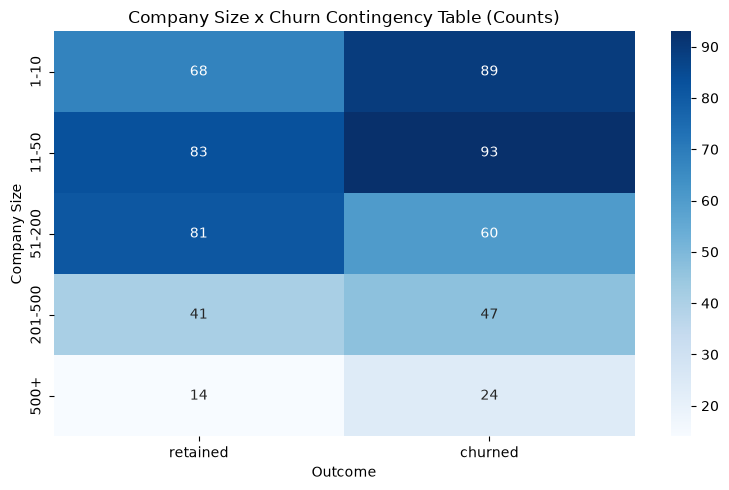

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(size_churn_crosstab, annot=True, fmt="d", cmap="Blues", ax=ax)

ax.set_title("Company Size x Churn Contingency Table (Counts)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Company Size")

plt.tight_layout()
plt.show()

In [29]:
size_churn_table = Table(size_churn_crosstab)
chi2_result_size = size_churn_table.test_nominal_association()

print(f"Chi-square statistic: {chi2_result_size.statistic:.3f}")
print(f"Degrees of freedom:   {chi2_result_size.df}")
print(f"P-value:              {chi2_result_size.pvalue:.6g}")

Chi-square statistic: 8.435
Degrees of freedom:   4
P-value:              0.0768946


### Chi-Square Test: Company Size and Churn Association

The chi-square test on the company_size × churn table gives χ² = 8.435, df = 4, p = 0.077 — above the conventional 0.05 threshold, so we fail to reject the null hypothesis that company size and churn are independent. Churn rates by size are 57% (1-10), 53% (11-50), 43% (51-200), 53% (201-500), and 63% (500+) — the 51-200 bucket clearly dips, matching the earlier channel × size heatmap, but the pattern isn't monotonic with size and the dip isn't large enough, given the sample sizes in each bucket, to count as a statistically significant association. Of the four candidate drivers, company_size is the weakest — on this evidence alone, it doesn't clear the bar that plan, billing_cycle, and acquisition_channel all did.

## Which Factors Matter Once You Control for All Four at Once?

Each factor above was tested on its own, but plan, billing cycle, acquisition channel, and company size might correlate with each other — an association found individually could just be riding on one of the others. The logistic regression below puts all four into one model, so we can see which factors remain statistically significant predictors of churn once every other factor is accounted for.

In [30]:
%%sql result_7 <<
SELECT plan, billing_cycle, acquisition_channel, company_size, churned
FROM subscriptions;

Running query in 'duckdb://'

In [31]:
full_logit_df = result_7.copy()
full_logit_df["churned"] = full_logit_df["churned"].astype(int)

full_logit_model = smf.logit(
    "churned ~ C(plan, Treatment(reference='Starter'))"
    " + C(billing_cycle)"
    " + C(acquisition_channel, Treatment(reference='Organic Search'))"
    " + C(company_size, Treatment(reference='1-10'))",
    data=full_logit_df,
).fit()

print(full_logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.603295
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                  600
Model:                          Logit   Df Residuals:                      586
Method:                           MLE   Df Model:                           13
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                  0.1284
Time:                        13:55:11   Log-Likelihood:                -361.98
converged:                       True   LL-Null:                       -415.32
Covariance Type:            nonrobust   LLR p-value:                 8.272e-17
                                                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------

In [32]:
full_odds_ratios = pd.DataFrame({
    "coef": full_logit_model.params,
    "odds_ratio": full_logit_model.params.apply(math.exp),
    "ci_lower_or": full_logit_model.conf_int()[0].apply(math.exp),
    "ci_upper_or": full_logit_model.conf_int()[1].apply(math.exp),
    "p_value": full_logit_model.pvalues,
})
full_odds_ratios

,coef,odds_ratio,ci_lower_or,ci_upper_or,p_value
Intercept,0.255137,1.290639,0.739950,2.251164,3.687124e-01
"C(plan, Treatment(reference='Starter'))[T.Business]",-1.299094,0.272779,0.172939,0.430258,2.308937e-08
"C(plan, Treatment(reference='Starter'))[T.Enterprise]",-2.247972,0.105613,0.049619,0.224794,5.457684e-09
"C(plan, Treatment(reference='Starter'))[T.Professional]",-0.953552,0.385370,0.248361,0.597959,2.098498e-05
C(billing_cycle)[T.Monthly],0.926956,2.526805,1.761313,3.624991,4.800134e-07
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Direct Sales]",-0.450185,0.637510,0.323165,1.257623,1.940476e-01
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Paid Ads]",0.401842,1.494575,0.881743,2.533340,1.355637e-01
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Partner]",0.576010,1.778926,1.017432,3.110358,4.332242e-02
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Referral]",0.702556,2.018907,1.190424,3.423976,9.141719e-03
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Social Media]",0.501094,1.650525,0.821939,3.314400,1.589222e-01


In [33]:
print(f"Plan x billing_cycle model:          AIC = {logit_model.aic:.1f}, BIC = {logit_model.bic:.1f}")
print(f"Plan + billing_cycle + channel + size model: AIC = {full_logit_model.aic:.1f}, BIC = {full_logit_model.bic:.1f}")

Plan x billing_cycle model:          AIC = 762.2, BIC = 797.3
Plan + billing_cycle + channel + size model: AIC = 752.0, BIC = 813.5


### Logistic Regression: All Four Factors Together

Putting plan, billing_cycle, acquisition_channel, and company_size into one model shows:

- **Plan** remains highly significant for every level (Business p = 2.3e-08, Enterprise p = 5.5e-09, Professional p = 2.1e-05 vs. Starter), same graded pattern as before.
- **Billing cycle** remains highly significant (OR = 2.53, p < 0.001).
- **Acquisition channel**: Partner (OR = 1.78, p = 0.043) and Referral (OR = 2.02, p = 0.009) are individually significant vs. the Organic Search baseline; Direct Sales, Paid Ads, and Social Media are not (p > 0.13).
- **Company size**: only the 51-200 bucket is individually significant (OR = 0.52, p = 0.011) — those companies churn less than the 1-10 baseline; 11-50, 201-500, and 500+ are not (p > 0.55).

Individual dummy p-values only compare each category to its reference level, though — they can't tell us whether acquisition_channel or company_size matter *as a whole* once the others are controlled for. That requires a joint likelihood-ratio test on each block, which is what the next section does.

Model fit: AIC improves with the extra factors (752.0 vs. 762.2 for the plan × billing_cycle interaction model), but BIC gets worse (813.5 vs. 797.3), since BIC penalizes the extra parameters more heavily.

## Which Blocks Actually Matter? Likelihood-Ratio Tests for company_size and acquisition_channel

The individual coefficient p-values above only compare each category to its reference level (Starter, Organic Search, 1-10). They don't tell us whether `company_size` or `acquisition_channel` as a whole adds explanatory power once the other factors are controlled for. The same likelihood-ratio approach already used to test the plan × billing_cycle interaction (cell above testing `logit_model`) answers that directly: fit the model with the block removed, and compare its log-likelihood to `full_logit_model`'s.

In [34]:
from scipy.stats import chi2

reduced_no_size_model = smf.logit(
    "churned ~ C(plan, Treatment(reference='Starter'))"
    " + C(billing_cycle)"
    " + C(acquisition_channel, Treatment(reference='Organic Search'))",
    data=full_logit_df,
).fit()

lr_stat_size = 2 * (full_logit_model.llf - reduced_no_size_model.llf)
lr_df_size = full_logit_model.df_model - reduced_no_size_model.df_model
lr_pvalue_size = chi2.sf(lr_stat_size, lr_df_size)

print(f"LR statistic: {lr_stat_size:.3f}")
print(f"Degrees of freedom: {lr_df_size}")
print(f"P-value: {lr_pvalue_size:.6g}")

Optimization terminated successfully.
         Current function value: 0.610115
         Iterations 5
LR statistic: 8.184
Degrees of freedom: 4.0
P-value: 0.0850599


In [35]:
reduced_no_channel_model = smf.logit(
    "churned ~ C(plan, Treatment(reference='Starter'))"
    " + C(billing_cycle)"
    " + C(company_size, Treatment(reference='1-10'))",
    data=full_logit_df,
).fit()

lr_stat_channel = 2 * (full_logit_model.llf - reduced_no_channel_model.llf)
lr_df_channel = full_logit_model.df_model - reduced_no_channel_model.df_model
lr_pvalue_channel = chi2.sf(lr_stat_channel, lr_df_channel)

print(f"LR statistic: {lr_stat_channel:.3f}")
print(f"Degrees of freedom: {lr_df_channel}")
print(f"P-value: {lr_pvalue_channel:.6g}")

Optimization terminated successfully.
         Current function value: 0.616349
         Iterations 5
LR statistic: 15.665
Degrees of freedom: 5.0
P-value: 0.00786866


### Likelihood-Ratio Test Results

Removing `acquisition_channel` costs the model LR = 15.665 (df=5, p = 0.0079) — significant, confirming the block matters jointly, consistent with its standalone chi-square (p = 0.017) and the two individually-significant dummies (Partner, Referral).

Removing `company_size` costs LR = 8.184 (df=4, p = 0.085) — **not significant** at the 0.05 level. The full model above showed one individually significant category (51-200, p = 0.011), but one significant category out of four is exactly the kind of false lead a joint test is meant to catch — when tested as a whole, the block doesn't clear the bar. This agrees with its standalone chi-square (p = 0.077): company_size does not have a statistically detectable relationship with churn once properly tested.

## Final Simplified Model

Based on the LR test results above (not on eyeballing individual coefficients), we keep only the blocks that are jointly significant and refit.

In [36]:
ALPHA = 0.05

final_formula_terms = [
    "C(plan, Treatment(reference='Starter'))",
    "C(billing_cycle)",
]
if lr_pvalue_channel < ALPHA:
    final_formula_terms.append("C(acquisition_channel, Treatment(reference='Organic Search'))")
if lr_pvalue_size < ALPHA:
    final_formula_terms.append("C(company_size, Treatment(reference='1-10'))")

final_formula = "churned ~ " + " + ".join(final_formula_terms)
final_model = smf.logit(final_formula, data=full_logit_df).fit()

print(final_formula)
print(final_model.summary())

Optimization terminated successfully.
         Current function value: 0.610115
         Iterations 5
churned ~ C(plan, Treatment(reference='Starter')) + C(billing_cycle) + C(acquisition_channel, Treatment(reference='Organic Search'))
                           Logit Regression Results                           
Dep. Variable:                churned   No. Observations:                  600
Model:                          Logit   Df Residuals:                      590
Method:                           MLE   Df Model:                            9
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                  0.1186
Time:                        13:55:11   Log-Likelihood:                -366.07
converged:                       True   LL-Null:                       -415.32
Covariance Type:            nonrobust   LLR p-value:                 3.147e-17
                                                                                    coef    std err          z      P>|z|      [0.025

In [37]:
final_odds_ratios = pd.DataFrame({
    "coef": final_model.params,
    "odds_ratio": final_model.params.apply(math.exp),
    "ci_lower_or": final_model.conf_int()[0].apply(math.exp),
    "ci_upper_or": final_model.conf_int()[1].apply(math.exp),
    "p_value": final_model.pvalues,
})
final_odds_ratios

,coef,odds_ratio,ci_lower_or,ci_upper_or,p_value
Intercept,0.037399,1.038107,0.656939,1.640435,8.727254e-01
"C(plan, Treatment(reference='Starter'))[T.Business]",-1.270562,0.280674,0.179206,0.439593,2.848982e-08
"C(plan, Treatment(reference='Starter'))[T.Enterprise]",-2.224151,0.108159,0.051126,0.228816,5.967696e-09
"C(plan, Treatment(reference='Starter'))[T.Professional]",-0.951717,0.386078,0.249934,0.596381,1.789307e-05
C(billing_cycle)[T.Monthly],0.921803,2.513818,1.758952,3.592641,4.201666e-07
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Direct Sales]",-0.444569,0.641100,0.326902,1.257288,1.957698e-01
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Paid Ads]",0.394864,1.484183,0.879406,2.504872,1.392164e-01
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Partner]",0.602876,1.827366,1.054294,3.167301,3.168409e-02
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Referral]",0.700428,2.014616,1.194626,3.397445,8.616207e-03
"C(acquisition_channel, Treatment(reference='Organic Search'))[T.Social Media]",0.475347,1.608573,0.811437,3.188796,1.733582e-01


In [38]:
print(f"Full model (plan+billing+channel+size):     AIC = {full_logit_model.aic:.1f}, BIC = {full_logit_model.bic:.1f}")
print(f"Final simplified model:                     AIC = {final_model.aic:.1f}, BIC = {final_model.bic:.1f}")

Full model (plan+billing+channel+size):     AIC = 752.0, BIC = 813.5
Final simplified model:                     AIC = 752.1, BIC = 796.1


### Final Conclusion: Which of the Four Factors Actually Relate to Churn

The acquisition_channel LR test came back significant (p = 0.0079) but company_size's didn't (p = 0.085), so the properly-tested final model drops company_size and keeps `plan + billing_cycle + acquisition_channel`. Dropping company_size barely moves AIC (752.1 vs. 752.0) but meaningfully improves BIC (796.1 vs. 813.5) — exactly what we'd expect from removing four parameters that weren't jointly earning their keep.

Pulling together the chi-square tests, the full model, and the two LR tests:

- **Plan** — strong, independent driver (chi-square p = 3.5e-12; every level p < 0.001 in the full model).
- **Billing cycle** — strong, independent driver (chi-square p = 1.1e-06; OR = 2.53, p < 0.001).
- **Acquisition channel** — real, independent driver as a block (LR p = 0.0079), concentrated in two categories: Referral and Partner customers churn significantly more than Organic Search customers; the other three channels don't clearly differ from Organic Search.
- **Company size** — does **not** have a statistically detectable independent relationship with churn once properly tested as a block (LR p = 0.085), despite one category (51-200) looking individually significant in the full model (p = 0.011) — consistent with its non-significant standalone chi-square (p = 0.077), and the kind of false lead a joint test is designed to catch.

So of the four candidate factors, **plan, billing_cycle, and acquisition_channel have genuine, independent relationships with churn; company_size does not** once tested rigorously as a block rather than by eyeballing individual categories.

## Summary: What Drives Churn, and in Which Direction

Based on these observational associations — chi-square tests, a full multi-factor logistic regression, and likelihood-ratio tests confirming each factor's effect holds once the others are controlled for — three of the four candidate factors have a genuine, independent relationship with churn, and we can describe the direction of each:

- **Plan**: strongly associated with churn, with a graded effect — churn risk decreases steadily from Starter to Professional to Business to Enterprise. Enterprise customers have the lowest churn odds of any plan (OR = 0.11 vs. Starter), the largest reduction among the three upgrade tiers.
- **Billing cycle**: strongly associated with churn — customers on Monthly billing have roughly 2.5x the churn odds of customers on Annual billing.
- **Acquisition channel**: associated with churn, but the effect is concentrated in two channels rather than spread evenly — customers acquired via Partner or Referral have significantly higher churn odds than customers acquired via Organic Search; the other channels (Direct Sales, Paid Ads, Social Media) are not statistically distinguishable from Organic Search.
- **Company size**: not statistically associated with churn once tested properly as a block, despite one size bucket looking significant in isolation. We found no reliable evidence that company size independently predicts churn.

One important caveat: all of this is **observational, not causal**. The data shows who churns, not what would happen if we changed a customer's plan, billing cycle, or acquisition channel — customers who are already lower-risk may simply be more likely to self-select into Enterprise or Annual billing, rather than those choices themselves lowering risk. These findings are best treated as a prioritized set of hypotheses for the business to test (e.g. via upgrade incentives or a billing-cycle switch campaign) rather than as a proven playbook for reducing churn.

## The Highest-Risk Segment: Starter + Monthly + Referral/Partner

Since plan and billing_cycle don't interact (confirmed earlier: LR = 2.004, p = 0.57 — their effects are additive, not amplifying), we can combine all three risk factors directly to estimate the predicted churn probability for the specific customer profile the business should be most worried about, and contrast it with the lowest-risk profile.

In [39]:
risk_segments = pd.DataFrame({
    "segment": ["Highest risk: Starter + Monthly + Referral", "Highest risk: Starter + Monthly + Partner", "Lowest risk: Enterprise + Annual + Organic Search"],
    "plan": ["Starter", "Starter", "Enterprise"],
    "billing_cycle": ["Monthly", "Monthly", "Annual"],
    "acquisition_channel": ["Referral", "Partner", "Organic Search"],
})
risk_segments["predicted_churn_prob"] = final_model.predict(risk_segments)
risk_segments

,segment,plan,billing_cycle,acquisition_channel,predicted_churn_prob
0,Highest risk: Starter + Monthly + Referral,Starter,Monthly,Referral,0.840188
1,Highest risk: Starter + Monthly + Partner,Starter,Monthly,Partner,0.826651
2,Lowest risk: Enterprise + Annual + Organic Search,Enterprise,Annual,Organic Search,0.100946


The model predicts an 84.0% churn probability for a Starter + Monthly + Referral customer, and 82.7% for Starter + Monthly + Partner — compared to just 10.1% for the lowest-risk profile (Enterprise + Annual + Organic Search). That's roughly an 8x difference in predicted churn risk between the two ends of the spectrum, driven entirely by three factors stacking additively (no interaction effects needed to produce this gap).

This is the concrete, actionable version of the "highest-risk segment" the business should prioritize: customers on Starter plan, paying monthly, acquired through Referral or Partner channels. Any retention intervention (proactive outreach, targeted incentives to upgrade or switch to annual billing) will have the most impact if aimed at this specific combination rather than any single factor in isolation.